<a href="https://colab.research.google.com/github/24ai098-star/sujitha/blob/main/imdb%20movie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
print(f"Total reviews: {len(df_balanced)}")
print(df_balanced['sentiment'].value_counts())

# Display a sample of the data
display(df_balanced.head())

Total reviews: 5000
sentiment
positive    2500
negative    2500
Name: count, dtype: int64


,text,sentiment,label
0,"Why would this film be so good, but only gross...",positive,1
1,"The name ""cult movie"" is often given to films ...",negative,0
2,Another stinker from the PM Entertainment grou...,negative,0
3,It really isn't hard to understand this movie!...,positive,1
4,"Make no mistake, Maureen O'Sullivan is easily ...",positive,1


Classification Report:

              precision    recall  f1-score   support

    Negative       0.88      0.82      0.85       500
    Positive       0.83      0.89      0.86       500

    accuracy                           0.85      1000
   macro avg       0.86      0.85      0.85      1000
weighted avg       0.86      0.85      0.85      1000



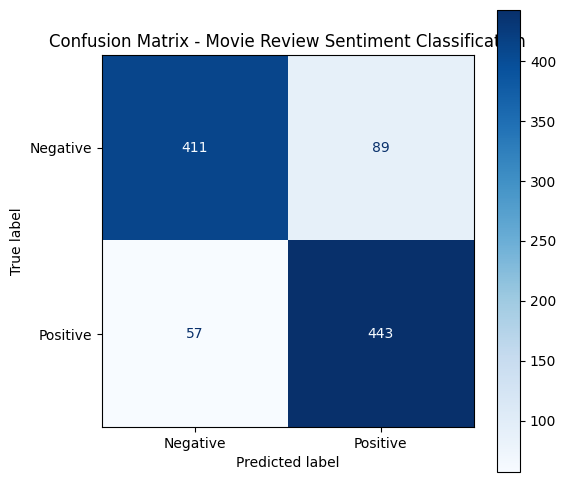

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Split the balanced dataset into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    df_balanced['text'],
    df_balanced['label'],
    test_size=0.2,
    random_state=42,
    stratify=df_balanced['label']
)

# Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train a Logistic Regression Classifier
model = LogisticRegression(random_state=42)
model.fit(X_train_tfidf, y_train)

# Predict and evaluate
y_pred = model.predict(X_test_tfidf)
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix - Movie Review Sentiment Classification')
plt.show()

In [ ]:
Here is the complete explanation, architecture, and code for performing **Sentiment Analysis on the IMDB Dataset using an LSTM (Long Short-Term Memory) Model**.

---

## 1. What is an LSTM Model?

In sentiment analysis, text data (movie reviews) is sequential. Traditional feed-forward neural networks cannot process sequence or word order effectively.

Standard **RNNs (Recurrent Neural Networks)** were introduced to handle sequential data, but they suffer from the **Vanishing Gradient Problem** (they forget information from long sentences).

**LSTM (Long Short-Term Memory)** solves this issue using specialized memory cells governed by three gates:

* **Forget Gate:** Decides what irrelevant information to discard from the cell state.
* **Input Gate:** Decides which new information to store in the cell state.
* **Output Gate:** Decides what the next hidden state/output should be based on the updated cell state.

---

## 2. Model Architecture Diagram

```text
[ Input Text / Review ]
          │
          ▼
┌──────────────────┐
│ Tokenization &   │  ---> Converts text words into numerical sequences
│ Padding          │  ---> Standardizes all inputs to a fixed length
└─────────┬────────┘
          │
          ▼
┌──────────────────┐
│ Embedding Layer  │  ---> Maps word IDs to dense 128-dimensional vectors
└─────────┬────────┘
          │
          ▼
┌──────────────────┐
│   LSTM Layer     │  ---> Processes sequence context and long-term memory
└─────────┬────────┘
          │
          ▼
┌──────────────────┐
│  Dropout Layer   │  ---> Prevents overfitting by deactivating random neurons
└─────────┬────────┘
          │
          ▼
┌──────────────────┐
│ Dense (Sigmoid)  │  ---> Outputs probability: 1 (Positive) or 0 (Negative)
└──────────────────┘

```

---

## 3. Python Implementation (Keras/TensorFlow Code)

Here is the Python code to load the dataset directly from the GitHub repository, preprocess the text, build the LSTM architecture, and train the model:

```python
import pandas as pd
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split

# 1. Load Dataset from GitHub URL
url = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
df = pd.read_csv(url)

# Convert labels: positive -> 1, negative -> 0
df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# 2. Text Preprocessing
vocab_size = 10000     # Top 10,000 most frequent words
max_length = 200       # Maximum review length (padded/truncated)

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(df['review'])

sequences = tokenizer.texts_to_sequences(df['review'])
padded_sequences = pad_sequences(sequences, maxlen=max_length, padding='post', truncating='post')

X = np.array(padded_sequences)
y = np.array(df['sentiment'])

# Split into Train and Test sets (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Build LSTM Model Architecture
embedding_dim = 128

model = Sequential([
    # Embedding Layer: Converts Word IDs to Dense Vectors
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),

    # LSTM Layer: Sequential Memory Processing
    LSTM(units=128, dropout=0.2, recurrent_dropout=0.2),

    # Output Layer: Binary Classification
    Dense(units=1, activation='sigmoid')
])

# Compile Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Print Architecture Summary
model.summary()

# 4. Train Model
# model.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_test, y_test))

```

---

## 4. Layer-by-Layer Architecture Breakdown

| Layer | Function | Purpose |
| --- | --- | --- |
| **1. Tokenizer & Padding** | Preprocessing | Converts string text into numerical vectors and ensures every review is equal to `max_length` (200 tokens). |
| **2. Embedding Layer** | `Embedding(10000, 128)` | Transforms discrete integer tokens into dense continuous vectors (128-dimensions), allowing the model to capture semantic relationships between words. |
| **3. LSTM Layer** | `LSTM(128)` | Contains 128 hidden memory units. Passes hidden states across word positions to retain context over the full length of the review. Dropout (0.2) reduces overfitting. |
| **4. Dense Output Layer** | `Dense(1, activation='sigmoid')` | Calculates a probability score between 0 and 1. Values $\ge 0.5$ indicate **Positive Sentiment**, while values $< 0.5$ indicate **Negative Sentiment**. |